<a href="https://colab.research.google.com/github/Roun-02/DSMBC-Online-Shoppers-Intention/blob/main/DSMBC_Online_Shoppers_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PREPROCESSING**
## Tahap lanjutan dari EDA: Online Shoppers Purchasing Intention

Notebook ini melanjutkan EDA (`DSMBC_Online_Shoppers_Intention_EDA.ipynb`). Tujuannya mengubah data mentah menjadi data yang siap dipakai model **tanpa kebocoran informasi (*data leakage*)**, dengan setiap keputusan berpijak pada temuan EDA.

## Dari catatan EDA ke tindakan preprocessing

| Catatan dari EDA | Tindakan di notebook ini | Bagian |
|---|---|---|
| 125 baris duplikat, semuanya `Revenue = False` | Dibuang **sebelum** split agar baris identik tidak masuk ke train dan test sekaligus | 2.2 |
| Anomali kecil (`BounceRates > ExitRates`, sesi tanpa halaman) | Dicek dampaknya, lalu dipertahankan | 2.3 |
| Fitur miring ke kanan dan outlier yang nyata | Outlier tidak dibuang; `log1p` + scaling untuk model linear, fitur mentah untuk model pohon | 3 |
| Kelas tidak seimbang (15,5% pembeli) | **Stratified split** dan bobot kelas; tidak ada resampling pada data uji | 4, 9 |
| `BounceRates`–`ExitRates` (r = 0,91) dan pasangan jumlah–durasi | Cek VIF; `BounceRates` dilepas **hanya** untuk jalur model linear | 5 |
| Kode `OperatingSystems`, `Browser`, `Region`, `TrafficType` adalah label | One-hot encoding; kode jarang digabung menjadi satu kelompok | 6, 7 |
| `PageValues` berpotensi *leakage* | Disiapkan dua versi fitur: **dengan** dan **tanpa** `PageValues` | 7, 8 |

**Prinsip yang dijaga:** semua yang "dipelajari" dari data (rata-rata untuk scaling, daftar kategori, kategori jarang) hanya dihitung dari **data latih**, lalu diterapkan ke data uji.

# **1. INISIALISASI**

In [21]:
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42

In [22]:
# Pakai file lokal bila ada, jika tidak ambil dari URL yang sama dengan EDA
url = "https://raw.githubusercontent.com/Roun-02/DSMBC-Online-Shoppers-Intention/refs/heads/main/online_shoppers_intention.csv"
local_candidates = ["online_shoppers_intention.csv", "data/online_shoppers_intention.csv",
                    "/mnt/user-data/uploads/online_shoppers_intention.csv"]
path = next((p for p in local_candidates if os.path.exists(p)), url)
df = pd.read_csv(path)

# Pengelompokan kolom (sama dengan EDA)
num_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
            'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates',
            'PageValues', 'SpecialDay']
cat_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
target = 'Revenue'
assert sorted(num_cols + cat_cols + [target]) == sorted(df.columns)

print("Sumber data:", path)
print("Ukuran data:", df.shape)

Sumber data: https://raw.githubusercontent.com/Roun-02/DSMBC-Online-Shoppers-Intention/refs/heads/main/online_shoppers_intention.csv
Ukuran data: (12330, 18)


# **2. PEMBERSIHAN DATA**

## 2.1 Tipe data

In [23]:
# Revenue dan Weekend bertipe boolean -> ubah ke 0/1 agar bisa dipakai model dan dihitung rata-ratanya
df[target] = df[target].astype(int)
df['Weekend'] = df['Weekend'].astype(int)

print("Missing value total:", df.isna().sum().sum())
df.dtypes.value_counts()

Missing value total: 0


,count
int64,9
float64,7
object,2


**Interpretasi:** tidak ada missing value. `Revenue` dan `Weekend` kini berupa 0/1, sehingga tersisa 9 kolom integer, 7 kolom desimal, dan 2 kolom teks (`Month`, `VisitorType`) yang akan di-encode.

## 2.2 Duplikat

In [24]:
dup_mask = df.duplicated(keep='first')
df_clean = df.drop_duplicates().reset_index(drop=True)

hasil = pd.DataFrame({
    'jumlah_sesi': [len(df), len(df_clean)],
    'pembeli': [df[target].sum(), df_clean[target].sum()],
    'conv_rate_%': [df[target].mean()*100, df_clean[target].mean()*100],
}, index=['sebelum', 'sesudah dibuang duplikat'])
display(hasil)
print("Duplikat yang dibuang:", dup_mask.sum(), "| Revenue=True di antara duplikat:", df.loc[dup_mask, target].sum())

,jumlah_sesi,pembeli,conv_rate_%
sebelum,12330,1908,15.474453
sesudah dibuang duplikat,12205,1908,15.632937


Duplikat yang dibuang: 125 | Revenue=True di antara duplikat: 0


**Interpretasi:** 125 duplikat dibuang dan seluruhnya `Revenue = False`, sehingga jumlah pembeli tetap 1.908 dan conversion rate hanya naik dari 15,47% ke 15,63%. Tersisa 12.205 sesi. Pembuangan dilakukan sebelum split agar baris identik tidak berada di data latih dan data uji sekaligus (yang akan membuat skor uji terlalu optimistis).

## 2.3 Anomali kecil dari EDA

In [25]:
page_total = df_clean['Administrative'] + df_clean['Informational'] + df_clean['ProductRelated']
m_be = df_clean['BounceRates'] > df_clean['ExitRates']
m_nopage = page_total == 0

anom = pd.DataFrame({
    'jumlah_sesi': [m_be.sum(), m_nopage.sum()],
    'persen_data': [m_be.mean()*100, m_nopage.mean()*100],
    'conv_rate_%': [df_clean.loc[m_be, target].mean()*100, df_clean.loc[m_nopage, target].mean()*100],
}, index=['BounceRates > ExitRates', 'Tanpa halaman sama sekali'])
display(anom)
print(f"Conv rate seluruh data: {df_clean[target].mean()*100:.2f}%")

,jumlah_sesi,persen_data,conv_rate_%
BounceRates > ExitRates,175,1.433839,10.857143
Tanpa halaman sama sekali,6,0.049160,0.000000


Conv rate seluruh data: 15.63%


**Interpretasi:** 175 sesi (1,4%) memiliki `BounceRates > ExitRates` dengan conversion rate 10,9%, sedikit di bawah rata-rata 15,6%, tetapi tidak ekstrem. Enam sesi tanpa halaman semuanya tidak membeli. Keduanya **dipertahankan**: jumlahnya kecil, dan tidak ada bukti bahwa label `Revenue`-nya salah.

# **3. OUTLIER DAN KEMIRINGAN (SKEWNESS)**

In [26]:
skew_cols = [c for c in num_cols if c != 'SpecialDay']     # SpecialDay hanya 0-1, tidak perlu log

# Apakah nilai ekstrem (di atas persentil 99) adalah sesi "aneh"? Lihat conversion rate-nya
rows = []
for c in skew_cols:
    thr = df_clean[c].quantile(.99)
    top = df_clean[c] > thr
    rows.append({'fitur': c, 'batas_P99': thr, 'jumlah_sesi_ekstrem': top.sum(),
                 'conv_rate_sesi_ekstrem_%': df_clean.loc[top, target].mean()*100})
display(pd.DataFrame(rows).set_index('fitur'))

,batas_P99,jumlah_sesi_ekstrem,conv_rate_sesi_ekstrem_%
fitur,,,
Administrative,14.000000,113,23.893805
Administrative_Duration,838.704889,123,21.138211
Informational,6.000000,83,24.096386
Informational_Duration,722.379200,123,26.016260
ProductRelated,221.000000,122,36.885246
ProductRelated_Duration,8704.271573,123,34.146341
BounceRates,0.200000,0,NaN
ExitRates,0.200000,0,NaN
PageValues,86.108689,123,86.991870


**Interpretasi:** sesi di atas persentil 99 bukan sesi "aneh". Conversion rate-nya 21–37% pada fitur halaman dan durasi, dan **87% pada `PageValues`**, jauh di atas rata-rata 15,6%. Membuang outlier berarti membuang pembeli yang paling jelas, sehingga **outlier tidak dibuang**. `BounceRates` dan `ExitRates` tidak punya nilai di atas P99 karena P99 sama dengan nilai maksimumnya (0,2).

,skew_asli,skew_setelah_log1p,persen_nol
Administrative,1.95,0.55,46.24
Administrative_Duration,5.59,0.24,47.34
Informational,4.01,2.01,78.44
Informational_Duration,7.54,1.90,80.29
ProductRelated,4.33,-0.04,0.31
ProductRelated_Duration,7.25,-1.43,5.16
BounceRates,3.16,3.08,45.21
ExitRates,2.23,2.13,0.62
PageValues,6.35,1.79,77.63


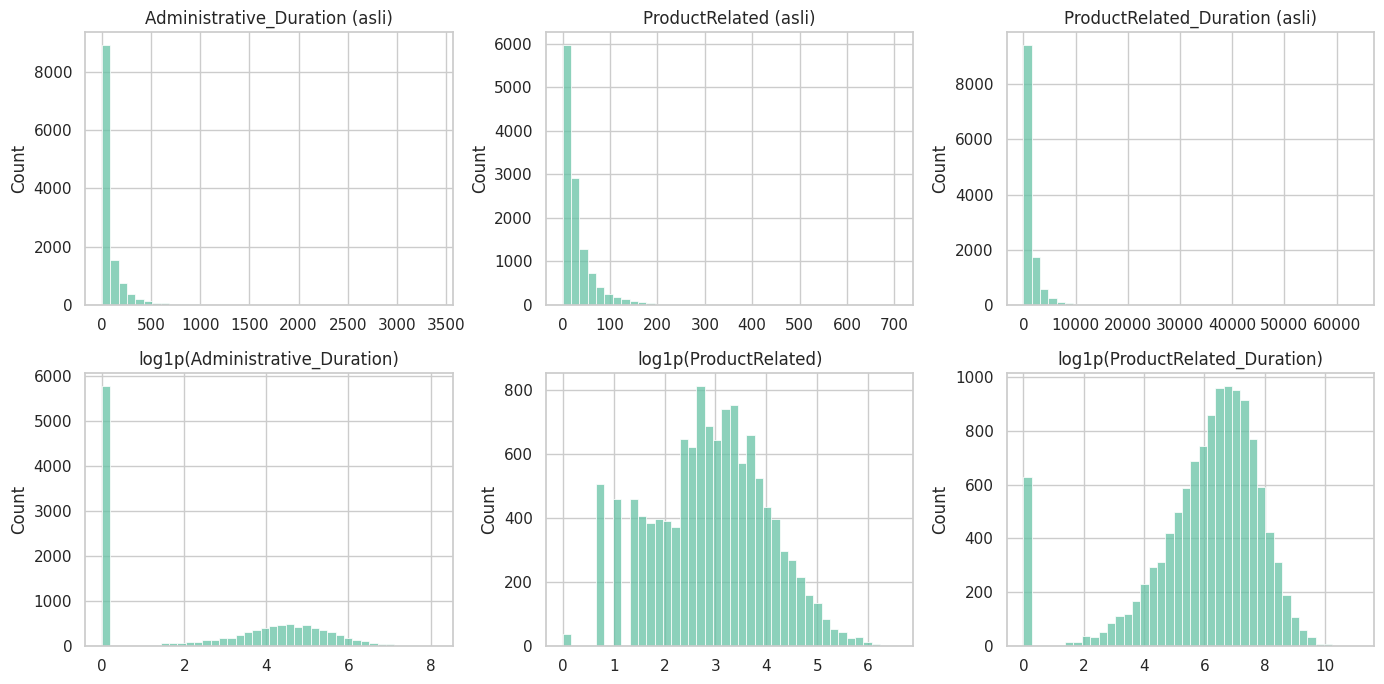

In [27]:
skew_tbl = pd.DataFrame({
    'skew_asli': df_clean[skew_cols].skew(),
    'skew_setelah_log1p': np.log1p(df_clean[skew_cols]).skew(),
    'persen_nol': (df_clean[skew_cols] == 0).mean() * 100,
})
display(skew_tbl.round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for j, c in enumerate(['Administrative_Duration', 'ProductRelated', 'ProductRelated_Duration']):
    sns.histplot(df_clean[c], bins=40, ax=axes[0, j]); axes[0, j].set_title(f"{c} (asli)")
    sns.histplot(np.log1p(df_clean[c]), bins=40, ax=axes[1, j]); axes[1, j].set_title(f"log1p({c})")
    axes[0, j].set_xlabel(""); axes[1, j].set_xlabel("")
plt.tight_layout(); plt.show()

**Interpretasi:** `log1p` menurunkan kemiringan secara nyata pada `Administrative_Duration` (5,59 → 0,24), `ProductRelated` (4,33 → −0,04), dan `PageValues` (6,35 → 1,79). Ada tiga catatan: (1) `Informational` dan durasinya masih miring (±2,0) karena 78–80% nilainya nol, dan tumpukan nol tidak hilang oleh log; (2) `BounceRates` dan `ExitRates` nyaris tidak berubah karena rentangnya hanya 0–0,2; (3) `ProductRelated_Duration` menjadi sedikit miring ke kiri (−1,43). Ini cukup baik untuk model linear; model pohon tidak memerlukan transformasi.

# **4. PEMBAGIAN DATA LATIH DAN DATA UJI**

Split dilakukan **sebelum** langkah yang "belajar" dari data (scaling, encoding, penggabungan kategori jarang). Dengan stratifikasi, proporsi pembeli di train dan test dijaga sama.

In [28]:
X = df_clean.drop(columns=target)
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

split_tbl = pd.DataFrame({
    'jumlah_sesi': [len(y_train), len(y_test)],
    'pembeli': [y_train.sum(), y_test.sum()],
    'conv_rate_%': [y_train.mean()*100, y_test.mean()*100],
}, index=['train', 'test'])
display(split_tbl)

# Cek sebaran bulan dan tipe pengunjung di kedua bagian
sel = pd.concat({'train': X_train['VisitorType'].value_counts(normalize=True),
                 'test': X_test['VisitorType'].value_counts(normalize=True)}, axis=1) * 100
display(sel.round(2))
sel_m = pd.concat({'train': X_train['Month'].value_counts(normalize=True),
                   'test': X_test['Month'].value_counts(normalize=True)}, axis=1) * 100
print(f"Selisih terbesar proporsi bulan train vs test: {(sel_m['train']-sel_m['test']).abs().max():.2f} poin persentase")

,jumlah_sesi,pembeli,conv_rate_%
train,9764,1526,15.628841
test,2441,382,15.649324


,train,test
VisitorType,,
Returning_Visitor,85.49,85.37
New_Visitor,13.82,14.09
Other,0.70,0.53


Selisih terbesar proporsi bulan train vs test: 1.41 poin persentase


**Interpretasi:** data terbagi menjadi 9.764 sesi latih dan 2.441 sesi uji dengan proporsi pembeli hampir identik (15,63% vs 15,65%). Proporsi tipe pengunjung selisih kurang dari 0,3 poin dan proporsi bulan selisih maksimum 1,41 poin, jadi data uji representatif terhadap data latih.

# **5. MULTIKOLINEARITAS**

Diukur dengan **VIF** (*Variance Inflation Factor*): VIF di atas ±5 berarti fitur tersebut sebagian besar bisa "ditebak" dari fitur lain. Dihitung pada data latih setelah `log1p` dan standardisasi.

In [29]:
Z = np.log1p(X_train[skew_cols])
Z = (Z - Z.mean()) / Z.std()

def vif_series(M):
    # VIF = elemen diagonal dari invers matriks korelasi
    R = np.corrcoef(M.values, rowvar=False)
    return pd.Series(np.diag(np.linalg.inv(R)), index=M.columns)

vif_tbl = pd.DataFrame({
    'VIF_semua_fitur': vif_series(Z),
    'VIF_tanpa_BounceRates': vif_series(Z.drop(columns='BounceRates')),
})
display(vif_tbl.round(2))

pairs = [('BounceRates', 'ExitRates'), ('ProductRelated', 'ProductRelated_Duration'),
         ('Administrative', 'Administrative_Duration'), ('Informational', 'Informational_Duration')]
print("Korelasi setelah log1p (data latih):")
for a, b in pairs:
    print(f"  {a:15s} vs {b:25s}: {Z[a].corr(Z[b]):.2f}")

,VIF_semua_fitur,VIF_tanpa_BounceRates
Administrative,7.40,7.37
Administrative_Duration,7.19,7.11
BounceRates,6.05,NaN
ExitRates,7.16,2.50
Informational,6.37,6.36
Informational_Duration,6.29,6.28
PageValues,1.13,1.12
ProductRelated,4.83,4.16
ProductRelated_Duration,6.24,5.60


Korelasi setelah log1p (data latih):
  BounceRates     vs ExitRates                : 0.89
  ProductRelated  vs ProductRelated_Duration  : 0.85
  Administrative  vs Administrative_Duration  : 0.92
  Informational   vs Informational_Duration   : 0.92


**Interpretasi:** setelah `log1p`, pasangan jumlah halaman dan durasinya berkorelasi 0,85–0,92 sehingga VIF-nya 6–7 (di atas batas ±5). `BounceRates` dan `ExitRates` berkorelasi 0,89. Melepas `BounceRates` menurunkan VIF `ExitRates` dari 7,16 ke 2,50. `ExitRates` yang dipertahankan karena kaitannya dengan `Revenue` lebih kuat di EDA (−0,21 vs −0,15). Pasangan jumlah–durasi **tidak dilepas**: keduanya membawa informasi berbeda (berapa banyak vs berapa lama) dan dampaknya bisa diredam dengan regularisasi pada Logistic Regression. `PageValues` hampir bebas kolinearitas (VIF 1,1).

# **6. KATEGORI JARANG PADA KODE NOMINAL**

In [30]:
nominal_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']   # kode = label, bukan urutan
MIN_FREQ = 100                                                           # kode dengan < 100 sesi di train digabung

rows = []
for c in nominal_cols:
    vc = X_train[c].value_counts()
    rare = vc[vc < MIN_FREQ]
    rows.append({'kolom': c, 'jumlah_kode': len(vc), 'kode_jarang': len(rare),
                 'kode_dipertahankan': len(vc) - len(rare),
                 'sesi_di_kode_jarang': rare.sum(), 'persen_sesi': rare.sum() / len(X_train) * 100,
                 'daftar_kode_jarang': sorted(rare.index.tolist())})
display(pd.DataFrame(rows).set_index('kolom').round(2))
print("VisitorType (train):", X_train['VisitorType'].value_counts().to_dict())

,jumlah_kode,kode_jarang,kode_dipertahankan,sesi_di_kode_jarang,persen_sesi,daftar_kode_jarang
kolom,,,,,,
OperatingSystems,8,4,4,86,0.88,"[5, 6, 7, 8]"
Browser,13,6,7,186,1.90,"[3, 7, 9, 11, 12, 13]"
Region,9,0,9,0,0.00,[]
TrafficType,19,8,11,136,1.39,"[7, 9, 14, 15, 16, 17, 18, 19]"


VisitorType (train): {'Returning_Visitor': 8347, 'New_Visitor': 1349, 'Other': 68}


**Interpretasi:** `Region` tidak punya kode jarang. Kode jarang hanya berasal dari `OperatingSystems` (4 kode, 86 sesi), `Browser` (6 kode, 186 sesi), dan `TrafficType` (8 kode, 136 sesi), yaitu 0,9–1,9% sesi per kolom. Penggabungan ini mengurangi jumlah kolom tanpa membuang banyak informasi. `VisitorType = Other` (68 sesi) tetap dipertahankan sebagai kategori sendiri karena maknanya jelas.

# **7. MEMBANGUN PIPELINE PREPROCESSING**

Dua jalur disiapkan karena kebutuhan modelnya berbeda:

| Jalur | Dipakai untuk | Perlakuan numerik | Kategorikal |
|---|---|---|---|
| `linear` | Logistic Regression | `log1p` + standardisasi; `BounceRates` dilepas | One-hot (kode jarang digabung) |
| `tree` | Decision Tree, Random Forest, Gradient Boosting | Dibiarkan apa adanya (pohon tidak terpengaruh skala atau skew) | One-hot (kode jarang digabung) |

In [31]:
log_tf = FunctionTransformer(np.log1p, feature_names_out='one-to-one')

def make_preprocessor(branch='linear', use_log=True, drop_bounce=True, drop_pagevalues=False):
    # branch: 'linear' atau 'tree'. Argumen lain dipakai untuk uji perbandingan di bagian ablation.
    num = list(num_cols)
    if drop_pagevalues:
        num.remove('PageValues')
    if branch == 'linear':
        if drop_bounce:
            num.remove('BounceRates')
        skew = [c for c in num if c != 'SpecialDay']
        scaler = Pipeline([('log', log_tf), ('scale', StandardScaler())]) if use_log else StandardScaler()
        numeric = [('num_skew', scaler, skew), ('num_lain', StandardScaler(), ['SpecialDay'])]
    else:
        numeric = [('num', 'passthrough', num)]
    categorical = [
        ('nominal', OneHotEncoder(min_frequency=MIN_FREQ, handle_unknown='infrequent_if_exist', sparse_output=False), nominal_cols),
        ('kategori', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Month', 'VisitorType']),
        ('biner', 'passthrough', ['Weekend']),
    ]
    return ColumnTransformer(numeric + categorical, verbose_feature_names_out=False).set_output(transform='pandas')

# Fit HANYA pada data latih, lalu terapkan ke data uji
prep_linear = make_preprocessor('linear').fit(X_train)
prep_tree = make_preprocessor('tree').fit(X_train)

Xtr_lin, Xte_lin = prep_linear.transform(X_train), prep_linear.transform(X_test)
Xtr_tree, Xte_tree = prep_tree.transform(X_train), prep_tree.transform(X_test)

print("Jalur linear :", Xtr_lin.shape, Xte_lin.shape)
print("Jalur tree   :", Xtr_tree.shape, Xte_tree.shape)
print("\nKode yang digabung menjadi 'infrequent' (dipelajari dari data latih):")
for c, cats in zip(nominal_cols, prep_linear.named_transformers_['nominal'].infrequent_categories_):
    print(f"  {c:17s}: {None if cats is None else [int(k) for k in cats]}")

Jalur linear : (9764, 57) (2441, 57)
Jalur tree   : (9764, 58) (2441, 58)

Kode yang digabung menjadi 'infrequent' (dipelajari dari data latih):
  OperatingSystems : [5, 6, 7, 8]
  Browser          : [3, 7, 9, 11, 12, 13]
  Region           : None
  TrafficType      : [7, 9, 14, 15, 16, 17, 18, 19]


**Interpretasi:** jalur linear menghasilkan 57 kolom dan jalur pohon 58 kolom (selisih satu kolom adalah `BounceRates`). Kode yang digabung dipelajari **hanya dari data latih** (misalnya OS 5–8, dan `TrafficType` 7, 9, 14–19). Kode yang belum pernah terlihat di data uji akan dimasukkan ke kelompok jarang bila kelompok itu ada.

In [32]:
# Uji kewajaran (sanity check)
assert not Xtr_lin.isna().any().any() and not Xte_lin.isna().any().any()
assert not Xtr_tree.isna().any().any() and not Xte_tree.isna().any().any()
assert list(Xtr_lin.columns) == list(Xte_lin.columns)

scaled = [c for c in Xtr_lin.columns if c in num_cols]
cek = pd.DataFrame({
    'mean_train': Xtr_lin[scaled].mean(), 'std_train': Xtr_lin[scaled].std(),
    'mean_test': Xte_lin[scaled].mean(), 'std_test': Xte_lin[scaled].std(),
})
display(cek.round(3))
print("Kolom hasil (jalur linear):")
print(list(Xtr_lin.columns))

,mean_train,std_train,mean_test,std_test
Administrative,0.0,1.0,-0.000,0.997
Administrative_Duration,-0.0,1.0,-0.002,0.995
Informational,0.0,1.0,-0.005,0.994
Informational_Duration,0.0,1.0,0.012,1.012
ProductRelated,-0.0,1.0,0.004,0.985
ProductRelated_Duration,0.0,1.0,-0.010,1.003
ExitRates,0.0,1.0,-0.000,1.002
PageValues,-0.0,1.0,0.006,1.011
SpecialDay,0.0,1.0,-0.010,0.993


Kolom hasil (jalur linear):
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems_1', 'OperatingSystems_2', 'OperatingSystems_3', 'OperatingSystems_4', 'OperatingSystems_infrequent_sklearn', 'Browser_1', 'Browser_2', 'Browser_4', 'Browser_5', 'Browser_6', 'Browser_8', 'Browser_10', 'Browser_infrequent_sklearn', 'Region_1', 'Region_2', 'Region_3', 'Region_4', 'Region_5', 'Region_6', 'Region_7', 'Region_8', 'Region_9', 'TrafficType_1', 'TrafficType_2', 'TrafficType_3', 'TrafficType_4', 'TrafficType_5', 'TrafficType_6', 'TrafficType_8', 'TrafficType_10', 'TrafficType_11', 'TrafficType_13', 'TrafficType_20', 'TrafficType_infrequent_sklearn', 'Month_Aug', 'Month_Dec', 'Month_Feb', 'Month_Jul', 'Month_June', 'Month_Mar', 'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep', 'VisitorType_New_Visitor', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'We

**Interpretasi:** tidak ada nilai kosong dan kolom data latih dan data uji identik. Pada data latih rata-rata tepat 0 dan standar deviasi tepat 1, sedangkan pada data uji hanya mendekati (rata-rata −0,01 sampai 0,01, std 0,99–1,01). Perbedaan kecil ini justru bukti bahwa scaler dipelajari dari data latih saja dan tidak "mengintip" data uji.

# **8. PENGUJIAN KEPUTUSAN PREPROCESSING (CROSS-VALIDATION PADA DATA LATIH)**

Untuk memastikan pilihan di atas tidak sekadar asumsi, empat konfigurasi dibandingkan dengan Logistic Regression sederhana memakai *stratified 5-fold CV* **pada data latih saja** (data uji tidak disentuh). Pipeline dipasang ulang di setiap fold sehingga tidak ada kebocoran. Metrik: **PR-AUC** (*average precision*).

> Ini bukan hasil model final. Tujuannya hanya menguji keputusan preprocessing.

In [33]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_pr_auc(prep):
    pipe = Pipeline([('prep', prep),
                     ('clf', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE))])
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='average_precision')
    return s.mean(), s.std()

konfigurasi = {
    '1. Tanpa log, semua fitur':                    make_preprocessor('linear', use_log=False, drop_bounce=False),
    '2. + log1p':                                   make_preprocessor('linear', use_log=True,  drop_bounce=False),
    '3. + log1p, tanpa BounceRates (pilihan)':      make_preprocessor('linear', use_log=True,  drop_bounce=True),
    '4. Pilihan, tanpa PageValues (skenario leakage)': make_preprocessor('linear', use_log=True, drop_bounce=True, drop_pagevalues=True),
}
rows = []
for nama, prep in konfigurasi.items():
    m, s = cv_pr_auc(prep)
    rows.append({'konfigurasi': nama, 'PR-AUC_rata2': m, 'std': s})
ablation = pd.DataFrame(rows).set_index('konfigurasi')
display(ablation.round(3))
print(f"Pembanding: PR-AUC model asal tebak = proporsi pembeli = {y_train.mean():.3f}")

,PR-AUC_rata2,std
konfigurasi,,
"1. Tanpa log, semua fitur",0.647,0.023
2. + log1p,0.663,0.023
"3. + log1p, tanpa BounceRates (pilihan)",0.664,0.022
"4. Pilihan, tanpa PageValues (skenario leakage)",0.332,0.032


Pembanding: PR-AUC model asal tebak = proporsi pembeli = 0.156


**Interpretasi:** `log1p` menaikkan PR-AUC dari 0,647 ke 0,663, dan melepas `BounceRates` hampir tidak mengubahnya (0,664), jadi kedua keputusan **tidak merugikan**. Selisih `log1p` (0,016) lebih kecil dari variasi antar fold (±0,02), sehingga dibaca sebagai "tidak merugikan dan kemungkinan sedikit membantu", bukan perbaikan pasti. Temuan terbesar: **tanpa `PageValues` PR-AUC turun separuh (0,664 → 0,332)**, walaupun masih sekitar 2 kali di atas tebakan acak (0,156). Artinya kemampuan prediksi model linear sangat bergantung pada satu fitur yang berisiko *leakage*. Jika `PageValues` tidak tersedia saat keputusan real-time, performa realistisnya jauh lebih rendah, jadi dua versi fitur dipertahankan.

# **9. PENANGANAN KELAS TIDAK SEIMBANG**

In [34]:
classes = np.array([0, 1])
w = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight = dict(zip(classes, w))
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()   # untuk XGBoost/LightGBM bila dipakai

print("Bobot kelas ('balanced')    :", {k: round(v, 3) for k, v in class_weight.items()})
print(f"Rasio bukan-pembeli : pembeli: {scale_pos_weight:.2f} : 1")
print("Proporsi kelas test (tidak diubah):", y_test.value_counts(normalize=True).round(4).to_dict())

Bobot kelas ('balanced')    : {np.int64(0): np.float64(0.593), np.int64(1): np.float64(3.199)}
Rasio bukan-pembeli : pembeli: 5.40 : 1
Proporsi kelas test (tidak diubah): {0: 0.8435, 1: 0.1565}


**Interpretasi:** bobot kelas `balanced` memberi pembeli bobot 3,20 dan bukan-pembeli 0,59, artinya satu pembeli dihitung sekitar 5,4 kali bukan-pembeli (sesuai rasio kelas di data latih). Data uji sengaja **tidak diubah** (84,35% : 15,65%) agar evaluasi mencerminkan kondisi nyata. Resampling seperti SMOTE belum dipakai; bila bobot kelas dirasa belum cukup, bisa dicoba nanti **di dalam** pipeline cross-validation, bukan sebelum split.

# **10. MENYIMPAN HASIL**

In [35]:
os.makedirs('data_processed', exist_ok=True)

# Data bersih + split (belum ditransformasi), supaya tahap modeling memakai pembagian yang sama persis
X_train.assign(Revenue=y_train).to_csv('data_processed/train.csv', index=False)
X_test.assign(Revenue=y_test).to_csv('data_processed/test.csv', index=False)

# Preprocessor yang sudah di-fit pada data latih (dengan dan tanpa PageValues)
joblib.dump({
    'linear': prep_linear,
    'tree': prep_tree,
    'linear_tanpa_pagevalues': make_preprocessor('linear', drop_pagevalues=True).fit(X_train),
    'tree_tanpa_pagevalues': make_preprocessor('tree', drop_pagevalues=True).fit(X_train),
    'class_weight': class_weight,
}, 'data_processed/preprocessors.joblib')

print(sorted(os.listdir('data_processed')))

['preprocessors.joblib', 'test.csv', 'test_linear.csv', 'test_tree.csv', 'train.csv', 'train_linear.csv', 'train_tree.csv']


In [36]:
# CSV hasil transformasi, hanya untuk dilihat/dipakai di luar notebook ini.
# Jangan dipakai ulang untuk CV atau tuning: scaling sudah dihitung dari seluruh data latih.
Xtr_lin.assign(Revenue=y_train).to_csv('data_processed/train_linear.csv', index=False)
Xte_lin.assign(Revenue=y_test).to_csv('data_processed/test_linear.csv', index=False)
Xtr_tree.assign(Revenue=y_train).to_csv('data_processed/train_tree.csv', index=False)
Xte_tree.assign(Revenue=y_test).to_csv('data_processed/test_tree.csv', index=False)

In [38]:
import zipfile

file_penting = ['train.csv', 'test.csv', 'preprocessors.joblib']
with zipfile.ZipFile('data_processed.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for f in file_penting:
        z.write(f'data_processed/{f}', arcname=f'data_processed/{f}')
print("Isi zip:", zipfile.ZipFile('data_processed.zip').namelist())

try:
    from google.colab import files
    files.download('data_processed.zip')
except ImportError:
    print("Bukan Google Colab, sel unduh dilewati. Zip ada di data_processed.zip.")

Isi zip: ['data_processed/train.csv', 'data_processed/test.csv', 'data_processed/preprocessors.joblib']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **11. KESIMPULAN PREPROCESSING**

## Ringkasan keputusan

| # | Keputusan | Alasan | Bukti |
|---|---|---|---|
| 1 | Revenue dan Weekend diubah menjadi 0/1 | Bisa langsung dipakai model | Tidak ada missing value |
| 2 | 125 duplikat dibuang sebelum split | Mencegah baris identik masuk train dan test | Semuanya `Revenue = False`; proporsi pembeli hanya bergeser 15,47% → 15,63% |
| 3 | Anomali kecil dipertahankan | Jumlahnya sedikit dan bukan label yang salah | Bagian 2.3 |
| 4 | Outlier tidak dibuang | Sesi ekstrem adalah perilaku nyata dan banyak berujung pembelian | Bagian 3 |
| 5 | `log1p` + standardisasi untuk jalur linear, fitur mentah untuk jalur pohon | Mengurangi kemiringan; pohon tidak membutuhkannya | Bagian 3 dan CV |
| 6 | Stratified split 80:20 | Proporsi pembeli train dan test sama | Bagian 4 |
| 7 | `BounceRates` dilepas hanya di jalur linear | Mengurangi VIF `ExitRates` tanpa menurunkan PR-AUC | Bagian 5 dan CV |
| 8 | Kode OS, Browser, Region, TrafficType di-one-hot; kode < 100 sesi digabung | Kode adalah label; kategori kecil mudah overfit | Bagian 6–7 |
| 9 | Dua versi fitur: dengan dan tanpa `PageValues` | Menguji ketergantungan model pada fitur yang berisiko leakage | CV konfigurasi 3 vs 4 |
| 10 | Kelas tidak seimbang ditangani dengan bobot kelas, bukan resampling | Data uji tetap menggambarkan kondisi nyata | Bagian 9 |

## Catatan untuk tahap modeling
- Selalu pakai `make_preprocessor(...)` **di dalam** `Pipeline` saat cross-validation dan tuning agar scaling dan encoding dihitung ulang di tiap fold.
- Data uji dipakai **sekali** di akhir untuk evaluasi model terpilih.
- Evaluasi dengan PR-AUC, precision, recall, F1, dan confusion matrix. Threshold dipilih berdasarkan biaya intervensi, bukan 0,5 otomatis.
- Laporkan setiap model **dengan dan tanpa `PageValues`**.
- Karena tidak ada identitas pengguna, sesi dari pengguna yang sama masih bisa tersebar di train dan test. Skor uji kemungkinan sedikit optimistis.